# Feature Generation - Aviation Incident Classification

This notebook implements the feature engineering and representation stage for the NTSB aviation accident dataset (`clean_cases.json` – 22,863 incident records across 26 categories).

### Summary of Stages:
1. **Stratified Train/Test Split**: 80% training / 20% test split preserving class proportions across all 26 categories, fitted exclusively on training data to strictly prevent data leakage.
2. **Five Diverse Text Representations**:
   - **R1: Bag-of-Words** (`CountVectorizer` – unigrams)
   - **R2: Word TF-IDF** (`TfidfVectorizer` – unigrams & bigrams)
   - **R3: Character n-gram TF-IDF** (`TfidfVectorizer` – sub-word `char_wb` 3–5 n-grams)
   - **R4: LSA / TruncatedSVD** (Latent Semantic Analysis – 200 dense semantic topics)
   - **R5: Sentence-Transformers** (Dense contextual embeddings from `all-MiniLM-L6-v2`)
3. **Feature Space Analysis**: Dimensionality & sparsity audit, class-specific statistical $\chi^2$ feature relevance, and 2D semantic projection.


## 1. Environment Setup & Data Ingestion

In [1]:
import os
import json
import time
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_selection import chi2
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sentence_transformers import SentenceTransformer

# Visualization styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 10

RANDOM_STATE = 42

C:\dev\AviationIncidents\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Load cleaned incident records
data_path = "clean_cases.json" if os.path.exists("clean_cases.json") else os.path.join("data", "clean_cases.json")
df = pd.read_json(data_path)

print(f"Dataset Dimensions: {df.shape[0]} rows, {df.shape[1]} columns")
print(f"Number of Incident Classes: {df['label'].nunique()}")
print(f"Text Columns Available: 'analysisNarrative' (raw context), 'text_lemmatized' (cleaned tokens)")

Dataset Dimensions: 22863 rows, 8 columns
Number of Incident Classes: 26
Text Columns Available: 'analysisNarrative' (raw context), 'text_lemmatized' (cleaned tokens)


## 2. Train / Test Split (Stratified Partitioning)

To evaluate generalization accurately and eliminate data leakage, we partition the dataset into an 80% training set and a 20% test set with stratification by target label (`label`). All feature extractors and dimensionality reduction models are fitted exclusively on the training split and subsequently applied via transformation to the test split.

In [3]:
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    df[['analysisNarrative', 'text_lemmatized']],
    df['label'],
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=df['label']
)

print(f"Training Samples : {len(X_train_raw):,} ({len(X_train_raw)/len(df)*100:.1f}%)")
print(f"Test Samples     : {len(X_test_raw):,} ({len(X_test_raw)/len(df)*100:.1f}%)")
print(f"Identical class count in train and test: {y_train.nunique()} == {y_test.nunique()} classes")

Training Samples : 18,290 (80.0%)
Test Samples     : 4,573 (20.0%)
Identical class count in train and test: 26 == 26 classes


## 3. Five Diverse Feature Representations

We extract five distinct feature spaces spanning sparse lexical counts, sub-word n-grams, decomposed semantic topics, and deep contextual neural embeddings.

In [4]:
feature_matrices = {}
execution_times = {}

### 3.1 Representation 1: Bag-of-Words (CountVectorizer)
Constructs a sparse matrix of raw term occurrences across the lemmatized narrative text.

In [5]:
t0 = time.time()

bow_vectorizer = CountVectorizer(
    min_df=3,
    max_df=0.90,
    max_features=5000
)

X_train_bow = bow_vectorizer.fit_transform(X_train_raw['text_lemmatized'])
X_test_bow = bow_vectorizer.transform(X_test_raw['text_lemmatized'])

execution_times['R1_BoW'] = time.time() - t0
feature_matrices['R1_BoW'] = (X_train_bow, X_test_bow)

print(f"R1 (Bag-of-Words) completed in {execution_times['R1_BoW']:.2f}s | Shape: {X_train_bow.shape}")

R1 (Bag-of-Words) completed in 0.82s | Shape: (18290, 5000)


### 3.2 Representation 2: Word TF-IDF (Unigrams & Bigrams)
Applies Term Frequency - Inverse Document Frequency weighting with sublinear scaling and captures two-word phrases (e.g., *engine failure*, *crosswind gust*).

In [6]:
t0 = time.time()

tfidf_word_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=3,
    max_df=0.85,
    sublinear_tf=True,
    max_features=10000
)

X_train_tfidf_word = tfidf_word_vectorizer.fit_transform(X_train_raw['text_lemmatized'])
X_test_tfidf_word = tfidf_word_vectorizer.transform(X_test_raw['text_lemmatized'])

execution_times['R2_Word_TFIDF'] = time.time() - t0
feature_matrices['R2_Word_TFIDF'] = (X_train_tfidf_word, X_test_tfidf_word)

print(f"R2 (Word TF-IDF 1-2) completed in {execution_times['R2_Word_TFIDF']:.2f}s | Shape: {X_train_tfidf_word.shape}")

R2 (Word TF-IDF 1-2) completed in 2.77s | Shape: (18290, 10000)


### 3.3 Representation 3: Character n-gram TF-IDF (3–5 n-grams)
Extracts sub-word character n-grams bounded by word borders (`char_wb`), providing robustness against spelling variations, typographical errors, and domain abbreviations.

In [7]:
t0 = time.time()

tfidf_char_vectorizer = TfidfVectorizer(
    analyzer='char_wb',
    ngram_range=(3, 5),
    min_df=5,
    max_df=0.90,
    sublinear_tf=True,
    max_features=10000
)

X_train_tfidf_char = tfidf_char_vectorizer.fit_transform(X_train_raw['text_lemmatized'])
X_test_tfidf_char = tfidf_char_vectorizer.transform(X_test_raw['text_lemmatized'])

execution_times['R3_Char_TFIDF'] = time.time() - t0
feature_matrices['R3_Char_TFIDF'] = (X_train_tfidf_char, X_test_tfidf_char)

print(f"R3 (Char TF-IDF 3-5) completed in {execution_times['R3_Char_TFIDF']:.2f}s | Shape: {X_train_tfidf_char.shape}")

R3 (Char TF-IDF 3-5) completed in 10.68s | Shape: (18290, 10000)


### 3.4 Representation 4: LSA / TruncatedSVD (Latent Semantic Analysis)
Projects the 10,000-dimensional Word TF-IDF space into 200 dense continuous semantic latent dimensions via singular value decomposition.

In [8]:
t0 = time.time()

N_COMPONENTS = 200
lsa_svd = TruncatedSVD(n_components=N_COMPONENTS, random_state=RANDOM_STATE)

X_train_lsa = lsa_svd.fit_transform(X_train_tfidf_word)
X_test_lsa = lsa_svd.transform(X_test_tfidf_word)

execution_times['R4_LSA'] = time.time() - t0
feature_matrices['R4_LSA'] = (X_train_lsa, X_test_lsa)

explained_var = lsa_svd.explained_variance_ratio_.sum() * 100
print(f"R4 (LSA Dense 200) completed in {execution_times['R4_LSA']:.2f}s | Explained Variance: {explained_var:.2f}% | Shape: {X_train_lsa.shape}")

R4 (LSA Dense 200) completed in 2.47s | Explained Variance: 27.35% | Shape: (18290, 200)


### 3.5 Representation 5: Sentence-Transformers (Dense Contextual Embeddings)
Encodes raw narrative texts using the pretrained transformer model `all-MiniLM-L6-v2`, capturing complex syntactic and semantic context in 384-dimensional dense vectors.

In [9]:
t0 = time.time()

model_name = 'all-MiniLM-L6-v2'
sbert_model = SentenceTransformer(model_name)

# Encode raw narrative texts to preserve complete syntactic context
X_train_sbert = sbert_model.encode(
    X_train_raw['analysisNarrative'].tolist(),
    batch_size=64,
    show_progress_bar=False,
    convert_to_numpy=True
)

X_test_sbert = sbert_model.encode(
    X_test_raw['analysisNarrative'].tolist(),
    batch_size=64,
    show_progress_bar=False,
    convert_to_numpy=True
)

execution_times['R5_Sentence_Transformers'] = time.time() - t0
feature_matrices['R5_Sentence_Transformers'] = (X_train_sbert, X_test_sbert)

print(f"R5 (Sentence-Transformers) completed in {execution_times['R5_Sentence_Transformers']:.2f}s | Shape: {X_train_sbert.shape}")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 12877.47it/s]

R5 (Sentence-Transformers) completed in 255.59s | Shape: (18290, 384)


## 4. Feature Space Analysis

We compare dimensions, density properties, memory footprints, and domain discriminative power across all generated representations.

In [10]:
summary_rows = []
for name, (X_tr, X_te) in feature_matrices.items():
    is_sparse = hasattr(X_tr, "nnz")
    sparsity = (1.0 - X_tr.nnz / (X_tr.shape[0] * X_tr.shape[1])) * 100 if is_sparse else 0.0
    mem_mb = (X_tr.data.nbytes + X_tr.indices.nbytes + X_tr.indptr.nbytes) / (1024**2) if is_sparse else X_tr.nbytes / (1024**2)
    
    summary_rows.append({
        "Representation": name,
        "Type": "Sparse CSR" if is_sparse else "Dense NumPy",
        "Train Shape": str(X_tr.shape),
        "Test Shape": str(X_te.shape),
        "Sparsity (%)": f"{sparsity:.2f}%",
        "Memory (MB)": f"{mem_mb:.2f} MB",
        "Build Time (s)": f"{execution_times[name]:.2f}s"
    })

representations_df = pd.DataFrame(summary_rows)
representations_df

,Representation,Type,Train Shape,Test Shape,Sparsity (%),Memory (MB),Build Time (s)
0,R1_BoW,Sparse CSR,"(18290, 5000)","(4573, 5000)",98.55%,15.30 MB,0.82s
1,R2_Word_TFIDF,Sparse CSR,"(18290, 10000)","(4573, 10000)",98.84%,24.43 MB,2.77s
2,R3_Char_TFIDF,Sparse CSR,"(18290, 10000)","(4573, 10000)",90.27%,203.82 MB,10.68s
3,R4_LSA,Dense NumPy,"(18290, 200)","(4573, 200)",0.00%,27.91 MB,2.47s
4,R5_Sentence_Transformers,Dense NumPy,"(18290, 384)","(4573, 384)",0.00%,26.79 MB,255.59s


### 4.1 Most Discriminative Features per Class ($\chi^2$ Statistical Test)
The $\chi^2$ (Chi-Square) test measures statistical dependency between feature occurrences and incident class labels, identifying terms most strongly predictive of specific event types.

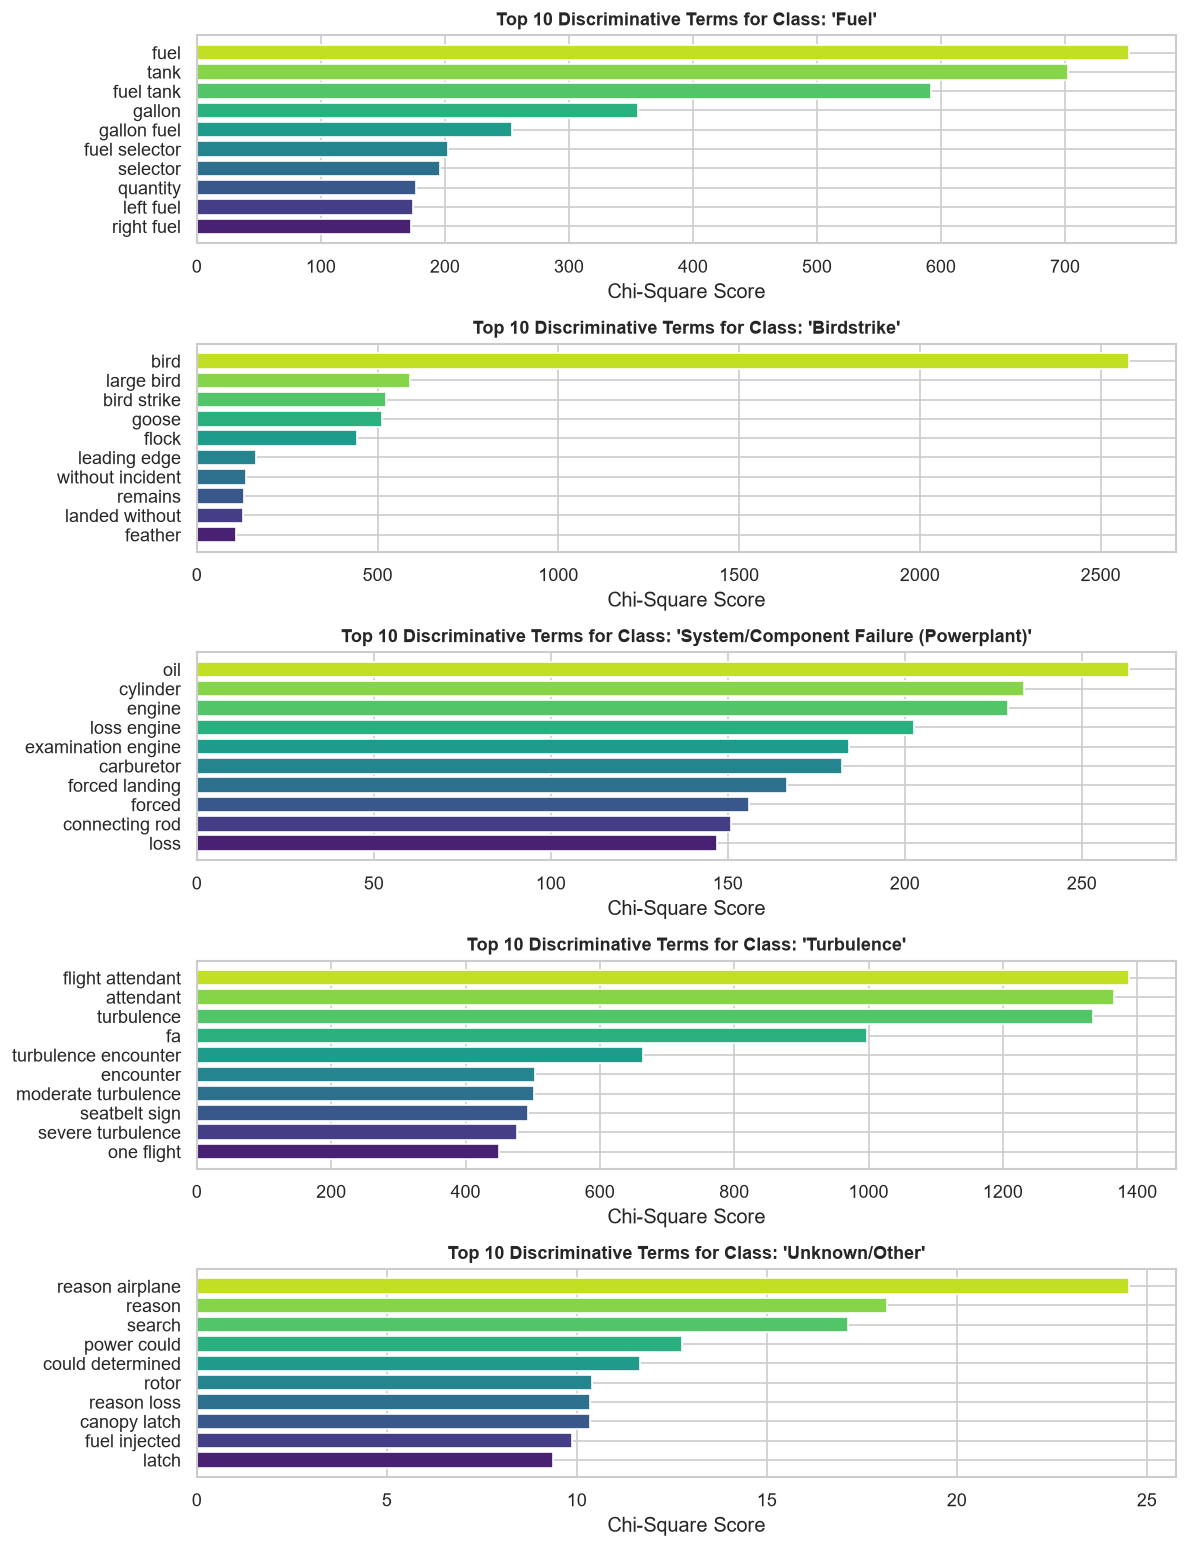

In [11]:
feature_names = tfidf_word_vectorizer.get_feature_names_out()
sample_classes = ["Fuel", "Birdstrike", "System/Component Failure (Powerplant)", "Turbulence", "Unknown/Other"]

fig, axes = plt.subplots(len(sample_classes), 1, figsize=(10, 13), sharex=False)

for i, cls in enumerate(sample_classes):
    binary_target = (y_train == cls).astype(int)
    chi2_scores, _ = chi2(X_train_tfidf_word, binary_target)
    
    top_indices = np.argsort(chi2_scores)[-10:]
    top_terms = [feature_names[idx] for idx in top_indices]
    top_scores = chi2_scores[top_indices]
    
    axes[i].barh(top_terms, top_scores, color=sns.color_palette("viridis", 10))
    axes[i].set_title(f"Top 10 Discriminative Terms for Class: '{cls}'", fontsize=11, fontweight="bold")
    axes[i].set_xlabel("Chi-Square Score")

plt.tight_layout()
plt.show()

### 4.2 2D Semantic Projection of Aviation Incidents
Projects incident narratives onto the first two components of Latent Semantic Analysis (TruncatedSVD) to inspect semantic separation among representative categories.

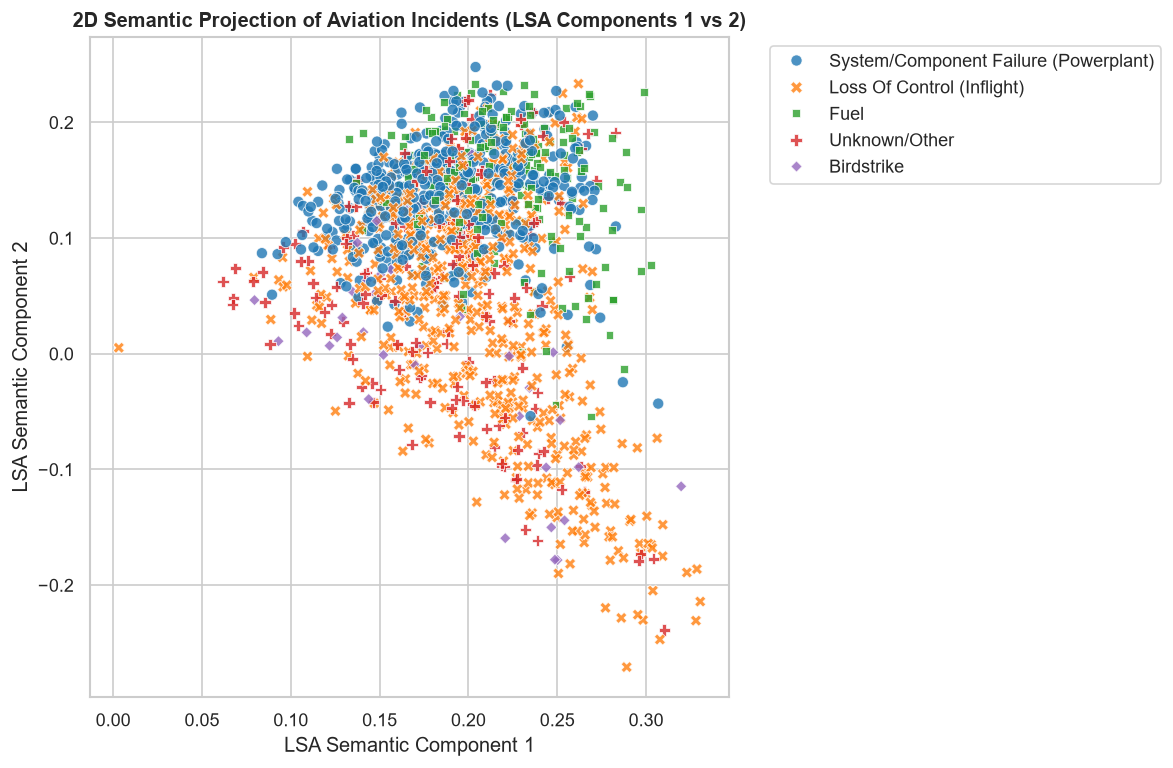

In [12]:
plot_classes = [
    "Loss Of Control (Inflight)",
    "System/Component Failure (Powerplant)",
    "Fuel",
    "Birdstrike",
    "Unknown/Other"
]

mask = y_train.isin(plot_classes)
sample_indices = mask[mask].sample(n=min(1500, mask.sum()), random_state=RANDOM_STATE).index
sample_locs = [X_train_raw.index.get_loc(idx) for idx in sample_indices]

lsa_2d_sample = X_train_lsa[sample_locs, :2]
labels_sample = y_train.loc[sample_indices]

plt.figure(figsize=(10, 6.5))
scatter_df = pd.DataFrame({
    'LSA Component 1': lsa_2d_sample[:, 0],
    'LSA Component 2': lsa_2d_sample[:, 1],
    'Incident Category': labels_sample.values
})

sns.scatterplot(
    data=scatter_df,
    x='LSA Component 1',
    y='LSA Component 2',
    hue='Incident Category',
    style='Incident Category',
    alpha=0.8,
    s=45,
    palette='tab10'
)

plt.title("2D Semantic Projection of Aviation Incidents (LSA Components 1 vs 2)", fontsize=12, fontweight="bold")
plt.xlabel("LSA Semantic Component 1")
plt.ylabel("LSA Semantic Component 2")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()